# Project 08: Energy Consumption & Peak Load Analysis

**Goal:** Analyse household electricity consumption, peak demand, time patterns, anomalies, and the relationship between consumption and weather.

**Dataset:** UCI Individual Household Electric Power Consumption (Sceaux, France; December 2006–November 2010; one-minute readings).  
**Weather:** Open-Meteo Historical Weather API (hourly reanalysis data for Sceaux).

> Important scope note: this dataset represents **one household**, not an entire city, utility grid, or multiple buildings. We will state this limitation in the final conclusions. The dataset does not contain a cumulative meter register, so a true meter reset cannot be confirmed; we will instead check timestamp gaps, duplicates, missing readings, and implausible/discontinuous power values.

**How to use:** Run the cells from top to bottom in Google Colab. Internet access is needed for downloading the dataset and weather data.

## 1. Import libraries

In [ ]:
import os
import zipfile
import requests
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

print("Libraries imported successfully")

Libraries imported successfully


## 2. Download the real electricity dataset

The UCI dataset contains 2,075,259 minute-level records. The raw file is semicolon-separated and missing numeric readings are represented by `?`.

Source: [UCI Machine Learning Repository – Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption)

In [ ]:
dataset_url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

response = requests.get(dataset_url, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as z:
    txt_name = [name for name in z.namelist() if name.endswith(".txt")][0]
    with z.open(txt_name) as file:
        raw = pd.read_csv(
            file,
            sep=";",
            na_values=["?"],
            low_memory=False
        )

print("Dataset downloaded.")
print("Shape:", raw.shape)
raw.head()

Dataset downloaded.
Shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000


## 3. Initial inspection

The common checklist asks for `head()`, `info()`, `describe()`, `shape`, and `isna().sum()`. We will run all of them.

In [ ]:
print("SHAPE")
print(raw.shape)

print("\\nHEAD")
display(raw.head())

print("\\nINFO")
raw.info()

print("\\nDESCRIPTIVE STATISTICS")
display(raw.describe(include="all").T)

print("\\nMISSING VALUES")
display(raw.isna().sum())

SHAPE
(2075259, 9)
\nHEAD


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000


\nINFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB
\nDESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,2075259,1442,25/11/2010,1440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,2075259,1440,17:24:00,1442,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Global_active_power,"2,049,280.000",NaN,NaN,NaN,1.092,1.057,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,"2,049,280.000",NaN,NaN,NaN,0.124,0.113,0.000,0.048,0.100,0.194,1.390
Voltage,"2,049,280.000",NaN,NaN,NaN,240.840,3.240,223.200,238.990,241.010,242.890,254.150
Global_intensity,"2,049,280.000",NaN,NaN,NaN,4.628,4.444,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,"2,049,280.000",NaN,NaN,NaN,1.122,6.153,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,"2,049,280.000",NaN,NaN,NaN,1.299,5.822,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,"2,049,280.000",NaN,NaN,NaN,6.458,8.437,0.000,0.000,1.000,17.000,31.000


\nMISSING VALUES


,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


## 4. Parse timestamps and validate sampling frequency

The original date format is `dd/mm/yyyy`; time is `hh:mm:ss`. We combine them into one datetime column and check whether the source timestamps are spaced one minute apart.

We check the interval **before dropping missing measurements**, because missing values do not mean the timestamp itself is absent.

In [ ]:
raw["datetime"] = pd.to_datetime(
    raw["Date"].astype(str) + " " + raw["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

raw = raw.dropna(subset=["datetime"]).copy()
raw = raw.sort_values("datetime")

time_diffs = raw["datetime"].diff().dropna()
print("Most common timestamp intervals:")
display(time_diffs.value_counts().head())

print("Rows with interval greater than one minute:", (time_diffs > pd.Timedelta(minutes=1)).sum())
print("Duplicate timestamps:", raw["datetime"].duplicated().sum())
print("Date range:", raw["datetime"].min(), "to", raw["datetime"].max())

Most common timestamp intervals:


,count
datetime,
0 days 00:01:00,2075258


Rows with interval greater than one minute: 0
Duplicate timestamps: 0
Date range: 2006-12-16 17:24:00 to 2010-11-26 21:02:00


## 5. Clean readings and detect data-quality issues

We convert measurement columns to numeric values. Then we:
- count missing values;
- count duplicate timestamps;
- flag negative active power/current readings;
- flag readings outside a broad voltage sanity range (180–260 V);
- flag unusually high active-power observations using the 99.9th percentile as a review threshold.

These flags are **quality checks**, not proof that every flagged observation is wrong. We preserve a separate anomaly flag for later analysis.

In [ ]:
measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in measurement_cols:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

print("Missing values before cleaning:")
display(raw[measurement_cols].isna().sum())

print("Duplicate timestamp rows:", raw["datetime"].duplicated().sum())

# Keep one record per timestamp if duplicates exist
raw = raw.drop_duplicates(subset="datetime", keep="first").copy()

# Quality flags are created before removing incomplete rows
raw["negative_power_flag"] = raw["Global_active_power"] < 0
raw["negative_current_flag"] = raw["Global_intensity"] < 0
raw["voltage_outside_180_260_flag"] = ~raw["Voltage"].between(180, 260)

high_power_cutoff = raw["Global_active_power"].quantile(0.999)
raw["extreme_power_flag"] = raw["Global_active_power"] > high_power_cutoff

quality_summary = pd.Series({
    "negative active power": raw["negative_power_flag"].sum(),
    "negative current": raw["negative_current_flag"].sum(),
    "voltage outside 180–260 V": raw["voltage_outside_180_260_flag"].sum(),
    "active power above 99.9th percentile": raw["extreme_power_flag"].sum()
}, name="flagged_rows")

display(quality_summary.to_frame())

# Keep rows with valid core power readings for the main analysis
clean = raw.dropna(subset=["Global_active_power"]).copy()
clean = clean[clean["Global_active_power"] >= 0].copy()
clean = clean.set_index("datetime").sort_index()

print("Clean dataset shape:", clean.shape)
display(clean.head())

Missing values before cleaning:


,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


Duplicate timestamp rows: 0


,flagged_rows
negative active power,0
negative current,0
voltage outside 180–260 V,25979
active power above 99.9th percentile,2048


Clean dataset shape: (2049280, 13)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,negative_power_flag,negative_current_flag,voltage_outside_180_260_flag,extreme_power_flag
datetime,,,,,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000,False,False,False,False
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000,False,False,False,False
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000,False,False,False,False
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000,False,False,False,False
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000,False,False,False,False


## 6. Create time features and consumption measures

`Global_active_power` is average active power in **kilowatts (kW)**. For each one-minute interval, estimated energy is `kW / 60` kilowatt-hours (kWh).

We will use:
- `power_kw`: instantaneous/interval-average demand;
- `energy_kwh`: estimated energy used during that one-minute interval.

In [ ]:
clean["power_kw"] = clean["Global_active_power"]
clean["energy_kwh"] = clean["power_kw"] / 60

clean["hour"] = clean.index.hour
clean["day_name"] = clean.index.day_name()
clean["day_of_week"] = clean.index.dayofweek
clean["is_weekend"] = clean["day_of_week"] >= 5
clean["month"] = clean.index.month
clean["year"] = clean.index.year
clean["season"] = clean["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

display(clean[["power_kw", "energy_kwh", "hour", "day_name", "is_weekend", "season"]].head())

,power_kw,energy_kwh,hour,day_name,is_weekend,season
datetime,,,,,,
2006-12-16 17:24:00,4.216,0.070,17,Saturday,True,Winter
2006-12-16 17:25:00,5.360,0.089,17,Saturday,True,Winter
2006-12-16 17:26:00,5.374,0.090,17,Saturday,True,Winter
2006-12-16 17:27:00,5.388,0.090,17,Saturday,True,Winter
2006-12-16 17:28:00,3.666,0.061,17,Saturday,True,Winter


## 7. Resample and aggregate with pandas

We aggregate the minute readings into hourly and daily summaries. Hourly mean kW represents average demand during that hour; summing the minute-level kWh values gives estimated hourly energy.

In [ ]:
hourly = clean.resample("h").agg(
    avg_power_kw=("power_kw", "mean"),
    max_power_kw=("power_kw", "max"),
    energy_kwh=("energy_kwh", "sum"),
    reading_count=("power_kw", "count")
)

daily = clean.resample("D").agg(
    avg_power_kw=("power_kw", "mean"),
    peak_power_kw=("power_kw", "max"),
    energy_kwh=("energy_kwh", "sum"),
    reading_count=("power_kw", "count")
)

print("Hourly data:")
display(hourly.head())
print("Daily data:")
display(daily.head())

Hourly data:


,avg_power_kw,max_power_kw,energy_kwh,reading_count
datetime,,,,
2006-12-16 17:00:00,4.223,7.706,2.534,36
2006-12-16 18:00:00,3.632,6.752,3.632,60
2006-12-16 19:00:00,3.400,4.070,3.400,60
2006-12-16 20:00:00,3.269,3.496,3.269,60
2006-12-16 21:00:00,3.056,3.502,3.056,60


Daily data:


,avg_power_kw,peak_power_kw,energy_kwh,reading_count
datetime,,,,
2006-12-16,3.053,7.706,20.153,396
2006-12-17,2.354,7.064,56.508,1440
2006-12-18,1.530,6.158,36.730,1440
2006-12-19,1.157,7.840,27.770,1440
2006-12-20,1.546,5.988,37.096,1440


## 8. NumPy peak quantiles, rolling calculations, and anomaly thresholds

We use NumPy percentiles to understand peak demand. A 95th percentile is a level that 95% of observations are at or below.

For anomaly screening, we use a rolling 24-hour mean and standard deviation on hourly average demand. A point above rolling mean + 3 standard deviations is flagged as a high-demand candidate. This is a statistical screening rule, not an automatic diagnosis.

In [ ]:
valid_hourly = hourly["avg_power_kw"].dropna().to_numpy()

peak_metrics = {
    "50th percentile (median) kW": np.percentile(valid_hourly, 50),
    "90th percentile kW": np.percentile(valid_hourly, 90),
    "95th percentile kW": np.percentile(valid_hourly, 95),
    "99th percentile kW": np.percentile(valid_hourly, 99),
    "Maximum hourly average kW": np.max(valid_hourly)
}
display(pd.Series(peak_metrics, name="value").to_frame())

hourly["rolling_mean_24h"] = hourly["avg_power_kw"].rolling(24, min_periods=12).mean()
hourly["rolling_std_24h"] = hourly["avg_power_kw"].rolling(24, min_periods=12).std()
hourly["anomaly_threshold_kw"] = (
    hourly["rolling_mean_24h"] + 3 * hourly["rolling_std_24h"]
)
hourly["high_demand_anomaly"] = (
    hourly["avg_power_kw"] > hourly["anomaly_threshold_kw"]
)

print("High-demand candidate hours:", int(hourly["high_demand_anomaly"].sum()))
display(hourly[hourly["high_demand_anomaly"]].head(10))

,value
50th percentile (median) kW,0.803
90th percentile kW,2.345
95th percentile kW,2.866
99th percentile kW,3.928
Maximum hourly average kW,6.561


High-demand candidate hours: 271


,avg_power_kw,max_power_kw,energy_kwh,reading_count,rolling_mean_24h,rolling_std_24h,anomaly_threshold_kw,high_demand_anomaly
datetime,,,,,,,,
2006-12-28 21:00:00,5.035,9.132,5.035,60,1.276,1.185,4.831,True
2007-01-02 17:00:00,2.136,2.678,2.136,60,0.685,0.468,2.089,True
2007-01-04 00:00:00,3.375,5.922,3.375,60,0.798,0.699,2.894,True
2007-01-07 13:00:00,3.332,5.806,3.332,60,0.841,0.688,2.906,True
2007-01-20 13:00:00,4.251,6.346,4.251,60,1.583,0.836,4.090,True
2007-01-21 19:00:00,5.330,8.018,5.330,60,2.095,1.047,5.235,True
2007-01-21 20:00:00,6.077,7.990,6.077,60,2.193,1.289,6.059,True
2007-02-06 21:00:00,2.779,4.672,2.779,60,0.896,0.614,2.737,True
2007-02-09 22:00:00,3.836,5.106,3.836,60,1.132,0.896,3.821,True


## 9. Weekday versus weekend and seasonal profiles

We compare average demand by hour for weekdays and weekends, and compare daily energy across seasons.

day_type,Weekday,Weekend
hour,,
0,0.569,0.889
1,0.468,0.721
2,0.435,0.596
3,0.412,0.529
4,0.426,0.490
5,0.431,0.512
6,0.875,0.579
7,1.715,0.961
8,1.580,1.158


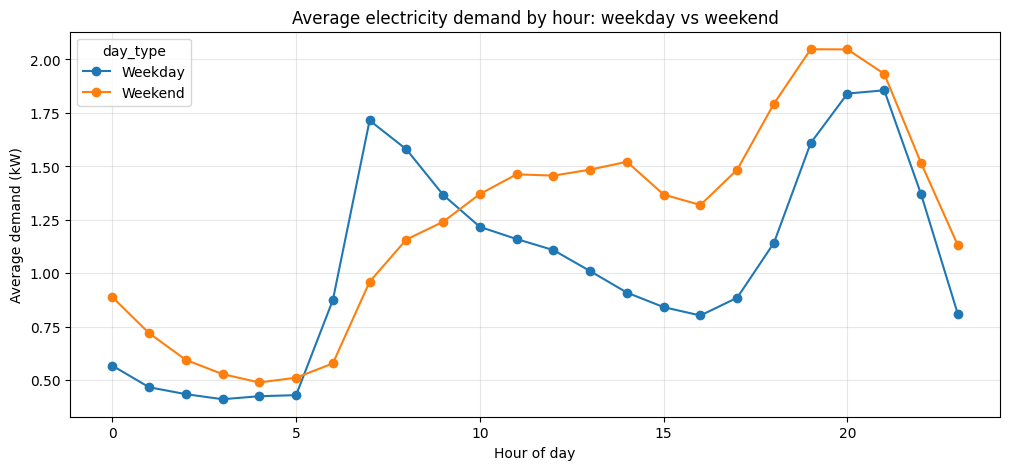

,mean,median,max,count
season,,,,
Winter,33.727,32.862,79.556,346
Spring,26.189,26.227,58.492,368
Summer,17.058,17.757,38.152,368
Autumn,26.943,26.277,56.755,360


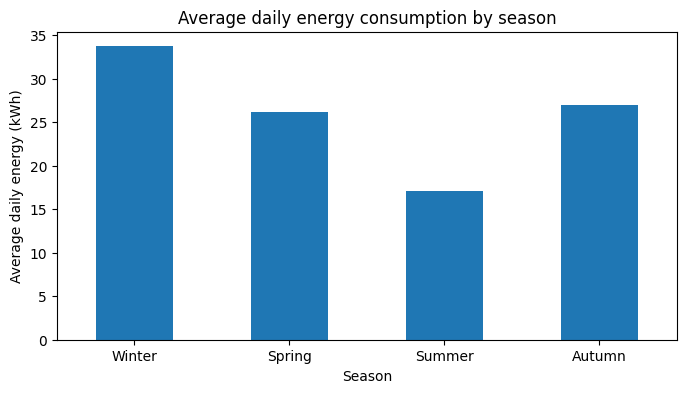

In [ ]:
clean["day_type"] = np.where(clean["is_weekend"], "Weekend", "Weekday")

hourly_profile = clean.groupby(["day_type", "hour"])["power_kw"].mean().unstack(0)
display(hourly_profile)

hourly_profile.plot(figsize=(12, 5), marker="o")
plt.title("Average electricity demand by hour: weekday vs weekend")
plt.xlabel("Hour of day")
plt.ylabel("Average demand (kW)")
plt.grid(True, alpha=0.3)
plt.show()

daily_with_season = daily.copy()
daily_with_season["season"] = daily_with_season.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

season_summary = daily_with_season.groupby("season")["energy_kwh"].agg(
    ["mean", "median", "max", "count"]
).reindex(["Winter", "Spring", "Summer", "Autumn"])

display(season_summary)
season_summary["mean"].plot(kind="bar", figsize=(8, 4))
plt.title("Average daily energy consumption by season")
plt.xlabel("Season")
plt.ylabel("Average daily energy (kWh)")
plt.xticks(rotation=0)
plt.show()

## 10. Join historical weather data

The household is in Sceaux, France. We retrieve hourly temperature, relative humidity, and precipitation from Open-Meteo's Historical Weather API, using the same `Europe/Paris` timezone as the electricity timestamps.

Weather is modelled reanalysis data, not a sensor installed inside the household.

In [ ]:
weather_url = "https://archive-api.open-meteo.com/v1/archive"
weather_params = {
    "latitude": 48.776,
    "longitude": 2.29,
    "start_date": clean.index.min().strftime("%Y-%m-%d"),
    "end_date": clean.index.max().strftime("%Y-%m-%d"),
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "timezone": "Europe/Paris"
}

weather_response = requests.get(weather_url, params=weather_params, timeout=180)
weather_response.raise_for_status()
weather_json = weather_response.json()

weather = pd.DataFrame(weather_json["hourly"])
weather["datetime"] = pd.to_datetime(weather["time"])
weather = weather.drop(columns=["time"]).set_index("datetime").sort_index()

print("Weather data shape:", weather.shape)
display(weather.head())

Weather data shape: (34608, 3)


,temperature_2m,relative_humidity_2m,precipitation
datetime,,,
2006-12-16 00:00:00,5.300,92,0.000
2006-12-16 01:00:00,5.100,93,0.000
2006-12-16 02:00:00,5.100,93,0.000
2006-12-16 03:00:00,5.300,94,0.000
2006-12-16 04:00:00,5.600,94,0.000


## 11. Merge electricity and weather using hourly timestamps

We join hourly electricity summaries with hourly weather values. We then inspect missing values after the join.

In [ ]:
analysis = hourly.join(weather, how="inner")

print("Joined dataset shape:", analysis.shape)
print("Missing values after join:")
display(analysis.isna().sum())

display(analysis.head())

Joined dataset shape: (34589, 11)
Missing values after join:


,0
avg_power_kw,421
max_power_kw,421
energy_kwh,0
reading_count,0
rolling_mean_24h,424
rolling_std_24h,424
anomaly_threshold_kw,424
high_demand_anomaly,0
temperature_2m,0
relative_humidity_2m,0


,avg_power_kw,max_power_kw,energy_kwh,reading_count,rolling_mean_24h,rolling_std_24h,anomaly_threshold_kw,high_demand_anomaly,temperature_2m,relative_humidity_2m,precipitation
datetime,,,,,,,,,,,
2006-12-16 17:00:00,4.223,7.706,2.534,36,NaN,NaN,NaN,False,6.700,93,0.800
2006-12-16 18:00:00,3.632,6.752,3.632,60,NaN,NaN,NaN,False,6.400,93,0.200
2006-12-16 19:00:00,3.400,4.070,3.400,60,NaN,NaN,NaN,False,6.200,92,0.000
2006-12-16 20:00:00,3.269,3.496,3.269,60,NaN,NaN,NaN,False,5.900,91,0.000
2006-12-16 21:00:00,3.056,3.502,3.056,60,NaN,NaN,NaN,False,5.100,92,0.000


## 12. Weather relationship analysis

We calculate correlations between average hourly demand and weather variables. Correlation describes association; it does **not** prove that weather caused a change in consumption.

,avg_power_kw,temperature_2m,relative_humidity_2m,precipitation
avg_power_kw,1.000,-0.189,0.061,0.005
temperature_2m,-0.189,1.000,-0.570,0.041
relative_humidity_2m,0.061,-0.570,1.000,0.158
precipitation,0.005,0.041,0.158,1.000


Correlation of demand with weather:


,avg_power_kw
temperature_2m,-0.189
precipitation,0.005
relative_humidity_2m,0.061


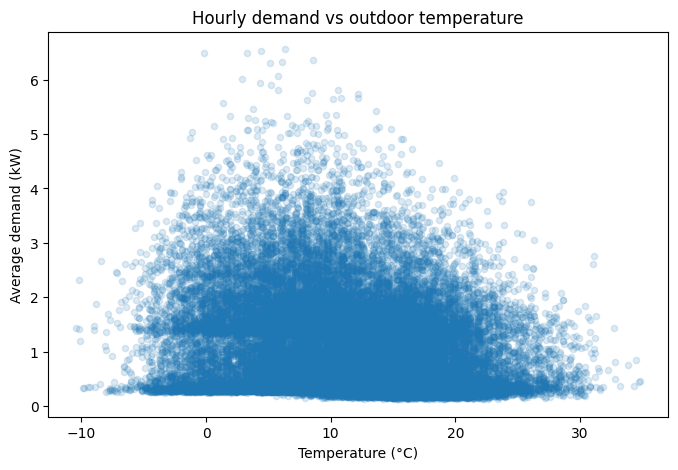

In [ ]:
weather_corr = analysis[
    ["avg_power_kw", "temperature_2m", "relative_humidity_2m", "precipitation"]
].corr()

display(weather_corr)

print("Correlation of demand with weather:")
display(weather_corr["avg_power_kw"].drop("avg_power_kw").sort_values())

analysis.plot(
    kind="scatter",
    x="temperature_2m",
    y="avg_power_kw",
    alpha=0.15,
    figsize=(8, 5)
)
plt.title("Hourly demand vs outdoor temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Average demand (kW)")
plt.show()

## 13. Quantify peak periods and load factor

We identify the highest-demand hours and summarize demand by hour of day.

For this project, load factor is calculated as:

**Load factor = average demand / peak demand**

A higher load factor means demand is more even relative to the peak; a lower value indicates a sharper peak. We calculate it for the complete hourly series and also for each day.

Average hourly demand: 1.092 kW
Peak hourly average demand: 6.561 kW
Overall load factor: 0.166


,avg_power_kw,max_power_kw,energy_kwh
datetime,,,
2008-11-23 18:00:00,6.561,7.724,6.561
2009-01-16 20:00:00,6.520,8.088,6.520
2008-02-02 19:00:00,6.496,8.716,6.496
2007-12-23 19:00:00,6.488,9.686,6.488
2007-02-22 21:00:00,6.364,9.410,6.364
2007-12-28 17:00:00,6.334,9.590,6.334
2008-11-23 20:00:00,6.311,8.556,6.311
2007-01-21 20:00:00,6.077,7.990,6.077
2008-01-26 19:00:00,6.014,9.666,6.014


,avg_power_kw,peak_power_kw,energy_kwh,load_factor
datetime,,,,
2006-12-16,3.053,7.706,20.153,0.396
2006-12-17,2.354,7.064,56.508,0.333
2006-12-18,1.530,6.158,36.730,0.249
2006-12-19,1.157,7.840,27.770,0.148
2006-12-20,1.546,5.988,37.096,0.258


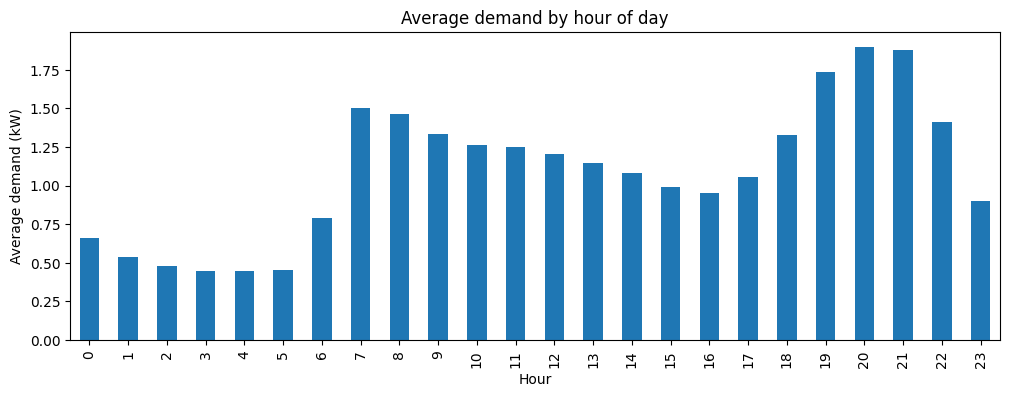

In [ ]:
overall_average_kw = hourly["avg_power_kw"].mean()
overall_peak_kw = hourly["avg_power_kw"].max()
overall_load_factor = overall_average_kw / overall_peak_kw

print(f"Average hourly demand: {overall_average_kw:.3f} kW")
print(f"Peak hourly average demand: {overall_peak_kw:.3f} kW")
print(f"Overall load factor: {overall_load_factor:.3f}")

top_peak_hours = hourly.nlargest(10, "avg_power_kw")[
    ["avg_power_kw", "max_power_kw", "energy_kwh"]
]
display(top_peak_hours)

daily["load_factor"] = daily["avg_power_kw"] / daily["peak_power_kw"]
display(daily[["avg_power_kw", "peak_power_kw", "energy_kwh", "load_factor"]].head())

hourly_of_day = hourly.groupby(hourly.index.hour)["avg_power_kw"].mean()
hourly_of_day.plot(kind="bar", figsize=(12, 4))
plt.title("Average demand by hour of day")
plt.xlabel("Hour")
plt.ylabel("Average demand (kW)")
plt.show()

## 14. Conservation scenario and uncertainty

We model simple hypothetical reductions in energy use. These are scenarios, not measured savings or guaranteed outcomes.

We also show how the estimated savings change if the achieved reduction is 5%, 10%, or 15%.

In [ ]:
baseline_energy_kwh = daily["energy_kwh"].sum()

scenario_rows = []
for reduction in [0.05, 0.10, 0.15]:
    saved = baseline_energy_kwh * reduction
    scenario_rows.append({
        "assumed_reduction": reduction,
        "baseline_energy_kwh": baseline_energy_kwh,
        "estimated_saving_kwh": saved,
        "remaining_energy_kwh": baseline_energy_kwh - saved
    })

scenario_table = pd.DataFrame(scenario_rows)
display(scenario_table)

# Simple uncertainty range around a nominal 10% conservation scenario
nominal_saving = baseline_energy_kwh * 0.10
uncertainty = pd.DataFrame({
    "case": ["Low (5%)", "Nominal (10%)", "High (15%)"],
    "estimated_saving_kwh": [
        baseline_energy_kwh * 0.05,
        nominal_saving,
        baseline_energy_kwh * 0.15
    ]
})
display(uncertainty)

,assumed_reduction,baseline_energy_kwh,estimated_saving_kwh,remaining_energy_kwh
0,0.050,"37,283.748","1,864.187","35,419.560"
1,0.100,"37,283.748","3,728.375","33,555.373"
2,0.150,"37,283.748","5,592.562","31,691.186"


,case,estimated_saving_kwh
0,Low (5%),"1,864.187"
1,Nominal (10%),"3,728.375"
2,High (15%),"5,592.562"


## 15. Final visualizations and anomaly log

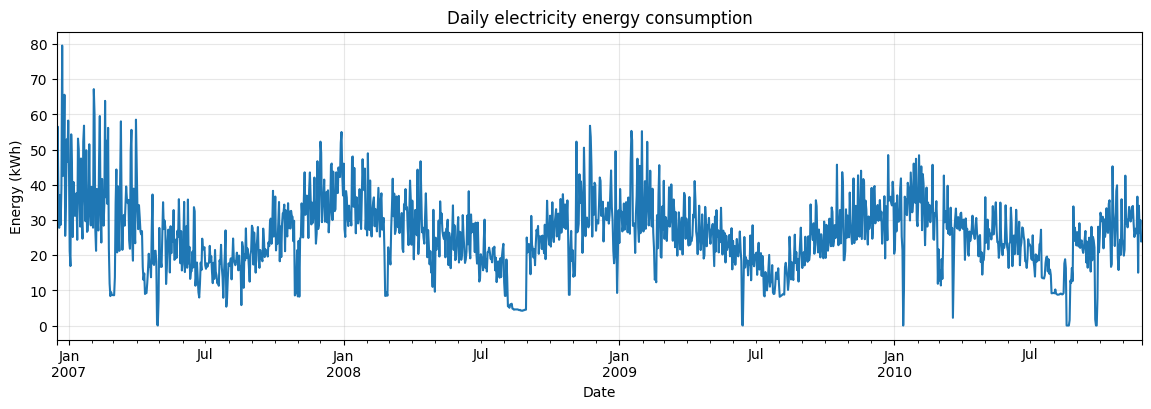

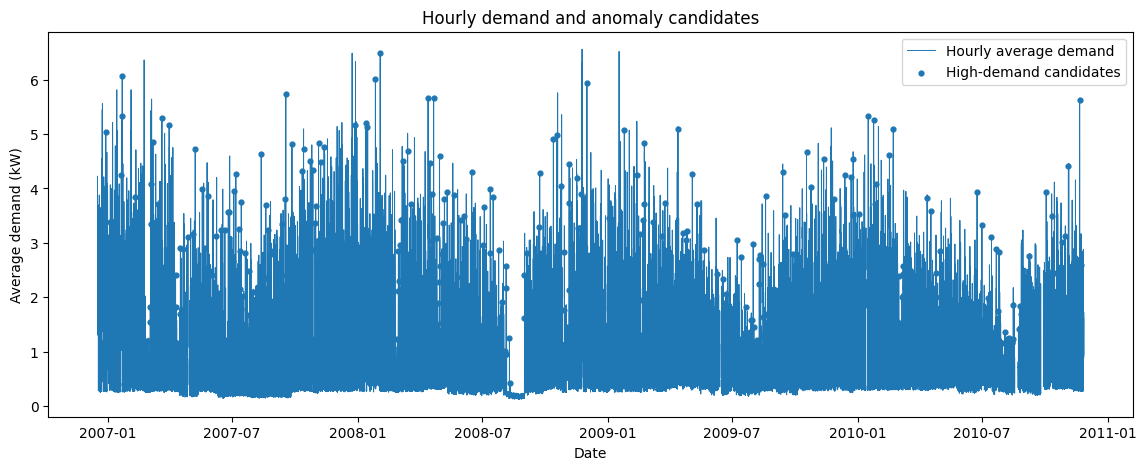

,avg_power_kw,rolling_mean_24h,rolling_std_24h,anomaly_threshold_kw
datetime,,,,
2006-12-28 21:00:00,5.035,1.276,1.185,4.831
2007-01-02 17:00:00,2.136,0.685,0.468,2.089
2007-01-04 00:00:00,3.375,0.798,0.699,2.894
2007-01-07 13:00:00,3.332,0.841,0.688,2.906
2007-01-20 13:00:00,4.251,1.583,0.836,4.090
2007-01-21 19:00:00,5.330,2.095,1.047,5.235
2007-01-21 20:00:00,6.077,2.193,1.289,6.059
2007-02-06 21:00:00,2.779,0.896,0.614,2.737
2007-02-09 22:00:00,3.836,1.132,0.896,3.821


Total candidate anomaly hours: 271


In [ ]:
# Daily energy trend
daily["energy_kwh"].plot(figsize=(14, 4))
plt.title("Daily electricity energy consumption")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.grid(True, alpha=0.3)
plt.show()

# Hourly average demand with high-demand anomaly candidates
plt.figure(figsize=(14, 5))
plt.plot(hourly.index, hourly["avg_power_kw"], label="Hourly average demand", linewidth=0.7)
flagged = hourly[hourly["high_demand_anomaly"]]
plt.scatter(flagged.index, flagged["avg_power_kw"], label="High-demand candidates", s=12)
plt.title("Hourly demand and anomaly candidates")
plt.xlabel("Date")
plt.ylabel("Average demand (kW)")
plt.legend()
plt.show()

anomaly_log = hourly.loc[
    hourly["high_demand_anomaly"],
    ["avg_power_kw", "rolling_mean_24h", "rolling_std_24h", "anomaly_threshold_kw"]
].copy()

display(anomaly_log.head(20))
print("Total candidate anomaly hours:", len(anomaly_log))

## 16. Export cleaned data, summaries, and anomaly log

These files can be downloaded from the Colab file panel or directly using the download cell.

In [ ]:
clean.reset_index().to_csv("cleaned_energy_data.csv", index=False)
hourly.to_csv("hourly_energy_summary.csv")
daily.to_csv("daily_energy_summary.csv")
analysis.to_csv("energy_weather_analysis.csv")
anomaly_log.to_csv("energy_anomaly_log.csv")

print("Exported:")
print("- cleaned_energy_data.csv")
print("- hourly_energy_summary.csv")
print("- daily_energy_summary.csv")
print("- energy_weather_analysis.csv")
print("- energy_anomaly_log.csv")

Exported:
- cleaned_energy_data.csv
- hourly_energy_summary.csv
- daily_energy_summary.csv
- energy_weather_analysis.csv
- energy_anomaly_log.csv


## 17. Project conclusions (complete after running)

Use the actual outputs from your notebook to write your conclusions. Do not invent values.

1. **Consumption pattern:** State the average and maximum hourly demand, and the dates/times of the largest peaks.
2. **Peak periods:** Identify the hours of day with the highest average demand.
3. **Calendar relationship:** Compare weekday and weekend profiles and mention the season with the highest average daily energy.
4. **Weather relationship:** Report the correlation with temperature, humidity, and precipitation. Explain that correlation is not causation.
5. **Data quality:** Report missing readings, duplicate timestamps, timestamp gaps, and the number of high-demand candidate anomalies. A true cumulative meter reset cannot be checked from this dataset.
6. **Conservation scenario:** Report the estimated kWh savings for the 5%, 10%, and 15% scenarios.
7. **Operational recommendations:** Suggest shifting flexible appliance use away from observed peak hours, investigating repeated high-demand periods, and monitoring demand during weather conditions associated with higher consumption.

### Limitations
- One household only; results cannot be generalized to all buildings or a power grid.
- Data is from 2006–2010, so it does not represent current household technology or present-day consumption.
- Weather values are reanalysis estimates for the area, not on-site measurements.
- Statistical anomaly flags require human review.
- Conservation scenarios are hypothetical estimates, not measured interventions.

### Dataset and weather references
- UCI dataset: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
- Dataset DOI: https://doi.org/10.24432/C58K54
- Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api